# Heterogeneous nucleation at liquid/polymorph interface 3

**Run the cells in order.** Each step writes into `./run/` (or `$OUT`) and the next one reads it, so the notebook is safe to re-run from the top: a step stops rather than starts if the one before it did not finish.

**Set `TRAJECTORY` in the next cell first.** It arrives pointing at the ten-frame sample in `sample-data/`, which exercises every step but is far too few frames to reproduce the published motifs — point it at your own trajectory, or at the full one from the Zenodo deposit, for a real run. The `*_KW` dicts in that same cell are where a step's parameters are overridden; an empty dict means the published value, and the cell shows the two overrides worth making for a quick pass.

**Steps 2 and 3 are the slow ones** — they train a network and fit a projection. **The reproduction section at the end needs no trajectory at all**: it redraws three published figures from a published run's stored arrays, and it is the part that checks this code against the paper.

Two things about how this notebook is built. The package modules are the procedure, and the scripts beside this file are the other front end to them — they take argv and suit a queue, these cells take Python arguments and suit a kernel. Nothing here shells out, so every step runs in this kernel, its output lands in the cell that called it, and a failure raises a traceback instead of an exit code; the cost is that a step killed by the OS or by the memory limit takes the kernel with it. And **an edit made in this notebook is lost** — the cells are generated by `tools/make-example-notebooks.py`, each note from its script's docstring, so change the docstring.

In [ ]:
# The trajectory this analysis runs on. A 10-frame sample of the
# published trajectory ships in sample-data/ so the stages can be run as soon as
# the repository is cloned -- enough to exercise every stage, far too few frames
# to reproduce the published motifs. Point this at your own trajectory, or at the
# full one from the Zenodo deposit, for a real run.
TRAJECTORY = "sample-data/8255188.NPT.T220.dump.gz"

import os, sys
sys.path.insert(0, "scripts")    # where config.py and the scripts live
# The sample is ALREADY spread across the published trajectory, so applying this
# dataset's published stride to it again throws most of it away -- where the
# stride is 500, it keeps 1 of the 10 frames. config.STRIDE reads $STRIDE, so
# ask for every frame whenever TRAJECTORY is the sample. On your own trajectory
# this does nothing and the published stride applies.
if "sample-data" in TRAJECTORY:
    os.environ.setdefault("STRIDE", "1")
import config
from config import flags         # kwargs -> stage flags; shared with the scripts
print("system :", config.SYSTEM)
print("kind   :", config.KIND)
print("stride :", config.STRIDE)
print("axis   :", config.AXIS, " (the projection axis motif_relabel ranks on)")
print("output :", os.path.relpath(config.OUT))
# A note, not an assertion: steps 1-5 need TRAJECTORY and stop on their own if
# it is not there, but the reproduction section at the end does not need it at
# all, and asserting here would block the whole notebook over a path it never
# reads.
if not os.path.exists(TRAJECTORY):
    print(f"\nnote: {TRAJECTORY!r} does not exist, so steps 1-5 will stop."
          "\n      Set TRAJECTORY to your own trajectory to run them. The"
          "\n      reproduction section at the end does not need it.")

# Per-stage overrides, passed straight through to that stage. An empty dict
# means its own default, which is the published value. For a smoke run on a
# couple of frames before committing to the real one:
#   FEATURIZE_KW = {**config.FEATURIZE, "frame_end": 2}
#   TRAIN_KW     = {**config.TRAIN, "epochs": 2}
#   CLUSTER_KW   = {"subsample": 1, "min_cluster_size": 50, "n_kmeans": 4}
FEATURIZE_KW = dict(config.FEATURIZE)   # this dataset's own stage-1 flags
TRAIN_KW     = dict(config.TRAIN)       # this dataset's own stage-2 flags
ENCODE_KW    = {}
PROJECT_KW   = {}
CLUSTER_KW   = {}
RELABEL_KW   = {}


def run_stage(module, script, argv):
    '''Run a pipeline stage IN THIS PROCESS and stop if it reports failure.

    Not a subprocess: the stage's output lands in the cell that called it, a
    failure raises here with its traceback rather than returning a bare exit
    code, and nothing depends on where `sys.executable` points. The cost is
    that a segfault or an out-of-memory kill inside a stage now takes the
    kernel with it, where a subprocess would only have killed itself.
    '''
    print(f"{script}  ->  {module.__name__}.main()\n")
    rc = module.main(argv)
    if rc:
        raise RuntimeError(f"{module.__name__} returned {rc}")
    return rc


## Step 1. Featurise: Steinhardt + SOAP per atom, cutoffs scaled by this system's d_nn.

Writes `features/`: 281 columns per atom -- 27 Steinhardt order parameters, 252
SOAP components, the Voronoi volume and the per-atom potential energy.

**Read the d_nn line it prints before trusting anything downstream.** Every
cutoff here is a fixed multiple of the first-neighbour distance -- the SOAP
radius, all three Steinhardt shells, the ring network -- so the stage measures
d_nn from your own frames and stops if it is more than 3% from the registry
value for this system. Nothing crashes on a wrong d_nn and nothing downstream
can undo one: the motifs simply describe a length scale you did not intend. If
this state point really does differ, pass --d-nn deliberately and say which
value you used.

In [ ]:
from icemotifs import systems as S
from icemotifs.lammps import iter_dump, count_frames
from icemotifs.pipeline import featurize as featurize_stage
from config import SYSTEM, KIND, STRIDE, OUT


def check_d_nn(path, system=SYSTEM, kind=KIND):
    """Measure the first-neighbour distance from frame 0, against the registry.

    Every cutoff downstream is a fixed multiple of d_nn -- the SOAP radius, the
    Steinhardt shells and the ring network at once -- so a wrong value rescales
    all of them together and nothing later in the pipeline can undo it.
    """
    sysdef = S.get(system)
    print(sysdef.describe())
    if kind != "dump":
        print("\n  d_nn is measured from a LAMMPS dump; this input is "
              f"{kind!r}, so check it yourself against the value above, or "
              "pass d_nn=... to featurize().")
        return None
    print(f"\n  frames in file  {count_frames(path)}")
    atoms, _ = next(iter(iter_dump(path, sysdef, allow_missing_energy=True,
                                   max_frames=1)))
    d = S.measure_d_nn(atoms)
    print(f"  atoms in frame  {len(atoms)}")
    print(f"  measured d_nn   {d:.3f} A   (registry says {sysdef.d_nn})")
    if abs(d - sysdef.d_nn) / sysdef.d_nn > 0.05:
        print("  !! more than 5% from the registry value. Use the measured one "
              "and say so in the SI.")
    return d


def featurize(input_path, *, system=SYSTEM, kind=KIND, out=None, stride=STRIDE,
              **extra):
    """Steinhardt + SOAP per atom -> OUT/features.

    A named-argument front end to `icemotifs.pipeline.featurize`, which is the
    published procedure; this does not reimplement it. `extra` passes any other
    flag of that stage through, e.g. frame_end=2, allow_missing_energy=True.
    """
    out = out or f"{OUT}/features"
    run_stage(featurize_stage, "scripts/01_featurize.py",
              ["--system", system, "--input", input_path, "--kind", kind,
               "--out", out, "--stride", str(stride)] + flags(extra))
    return out


assert os.path.exists(TRAJECTORY), (
    f"set TRAJECTORY in the setup cell first: {TRAJECTORY!r} does not exist")
check_d_nn(TRAJECTORY)
featurize(TRAJECTORY, **FEATURIZE_KW)

## Step 2. Train the VAE on the descriptors from step 1.

Writes `vae/`: the weights, the per-block scalers fitted on training rows only,
and the loss history. One of the two slow steps -- put `epochs` into TRAIN_KW
for a smoke run before committing to a real one.

Trained on this trajectory alone; no weights are carried in from anywhere, so
the vocabulary that comes out belongs to this dataset.

**The setting to understand is lambda_pred** (default 0.1, the published
value). It weights a head that predicts per-atom Voronoi volume and energy from
the latent. Neither is an encoder input, but a non-zero weight shapes the latent
so that both can be recovered from it -- so motifs separating on density is
partly by construction. Set it to 0 for a latent shaped by structure alone, and
you must set it to 0 if your trajectory carries no per-atom energy.

In [ ]:
from icemotifs.pipeline import train_vae as train_stage
from config import SYSTEM, OUT, need_stage


def train_vae(*, features=None, system=SYSTEM, out=None, **extra):
    """Train the VAE on the descriptors from step 1 -> OUT/vae.

    Named-argument front end to `icemotifs.pipeline.train_vae`. `extra` reaches
    that stage's own flags: epochs=2 for a smoke run, dim_z=..., beta_max=...,
    seed=..., device="cuda".
    """
    features = features or f"{OUT}/features"
    out = out or f"{OUT}/vae"
    need_stage(features, "scripts/01_featurize.py")
    run_stage(train_stage, "scripts/02_train_vae.py",
              ["--features", features, "--system", system, "--out", out]
              + flags(extra))
    return out


train_vae(**TRAIN_KW)

## Step 3. Encode to the latent Z, then project to 2-D (PCA then UMAP).

Writes `Z.npy` and `proj/`: the 2-D embedding **and the fitted reducer**. Keep
the reducer. Projecting a second trajectory THROUGH it is a different
experiment from fitting a new one, and having the file on disk is what makes
clear which of the two you did.

The other slow step. UMAP is fitted on a subsample and applied to the rest, and
its result depends on the thread count as well as the seed -- so an exact rerun
means the same `n_jobs`, not just the same `--seed`.

In [ ]:
from icemotifs.pipeline import encode_run as encode_stage
from icemotifs.pipeline import project as project_stage
from config import OUT, need_stage


def encode(*, features=None, run=None, out=None, **extra):
    """Encode the descriptors to the latent Z with the trained network."""
    features = features or f"{OUT}/features"
    run = run or f"{OUT}/vae"
    out = out or f"{OUT}/Z.npy"
    need_stage(run, "scripts/02_train_vae.py")
    run_stage(encode_stage, "scripts/03_project.py",
              ["--features", features, "--run", run, "--out", out]
              + flags(extra))
    return out


def project(*, z=None, out=None, **extra):
    """PCA (optional) then UMAP -> OUT/proj, with the fitted reducer saved.

    Keep reducer.pkl. Projecting a second trajectory THROUGH it is a different
    experiment from fitting a new one, and having the file on disk makes which
    you did unambiguous later. `extra` reaches the stage's flags: n_pca=...,
    fit_subsample=..., n_neighbors=..., min_dist=..., seed=..., n_jobs=...
    (n_jobs != 1 drops the UMAP seed, and that stage says so when it happens).
    """
    z = z or f"{OUT}/Z.npy"
    out = out or f"{OUT}/proj"
    run_stage(project_stage, "scripts/03_project.py",
              ["--z", z, "--out", out] + flags(extra))
    return out


encode(**ENCODE_KW)
project(**PROJECT_KW)

## Step 4. Vector-quantise the projection: HDBSCAN clusters, then k-means tiles.

Writes `motifs/`: `labels.npy` and `clustering.json`. **Quote two numbers from
that json -- the HDBSCAN cluster count and the intermediate fraction.** Its
field names are still `n_density_maxima` and `outlier_fraction`, which is what
the lines below print; they are the same two numbers.

The two stages produce two KINDS of label and they do not mean the same thing.
An HDBSCAN cluster is a region the data actually concentrates in. A k-means cell
is a tile over the intermediate regions -- the continuum between clusters, which
has no density peak for HDBSCAN to find. So the motif total is a measured number
plus your own choice of k, and reports a parameter as much as a result.

`min_cluster_size` and `n_kmeans` in CLUSTER_KW are the two knobs. On the
ten-frame sample the published values resolve far less than the published run
did -- that is the sample size, not a failure.

In [ ]:
import json, os, pickle
import numpy as np
from icemotifs.cluster import two_stage, assign_rest
from icemotifs.pipeline.cluster_motifs import PUBLISHED
from config import OUT, need_stage

# PUBLISHED is imported, not copied: these are the values the paper used, and a
# number retyped here would be a second source of truth that can drift.
print("published clustering parameters:", PUBLISHED)


def cluster_motifs(*, embedding=None, out=None,
                   subsample=PUBLISHED["subsample"],
                   min_cluster_size=PUBLISHED["min_cluster_size"],
                   min_samples=PUBLISHED["min_samples"],
                   n_kmeans=PUBLISHED["n_kmeans"],
                   seed=PUBLISHED["seed"]):
    """Two-stage vector quantisation, written against icemotifs.cluster.

    1. HDBSCAN on every `subsample`-th point -- a STRIDE, `E[::subsample]`, not
       a random draw -- which resolves the well-separated DENSITY MAXIMA.
    2. k-means over what HDBSCAN returned as outliers. Those are not noise:
       they are the intermediate continuum, which has no density maxima for a
       density method to find.
    3. Every remaining point takes the label of its nearest subsampled point.

    Writes labels.npy, clusterer.pkl and clustering.json -- the same three
    files `04_cluster.py` writes.
    """
    embedding = embedding or f"{OUT}/proj/embedding.npy"
    out = out or f"{OUT}/motifs"
    need_stage(os.path.dirname(embedding), "scripts/03_project.py")
    os.makedirs(out, exist_ok=True)

    E = np.load(embedding)
    sub = E[::subsample]
    print(f"embedding {E.shape}; clustering on every {subsample}th point: "
          f"{len(sub):,} of {len(E):,}")
    part = two_stage(sub, min_cluster_size=min_cluster_size,
                     min_samples=min_samples, n_kmeans=n_kmeans, seed=seed)
    labels, knn = assign_rest(E, sub, part.labels)

    np.save(os.path.join(out, "labels.npy"), labels)
    with open(os.path.join(out, "clusterer.pkl"), "wb") as fh:
        pickle.dump({"knn": knn, "sub_labels": part.labels,
                     "subsample": subsample}, fh)
    meta = dict(
        embedding=os.path.abspath(embedding), n_rows=int(len(E)),
        implementation=part.implementation, subsample=subsample,
        hdbscan=dict(min_cluster_size=min_cluster_size,
                     min_samples=min_samples, max_cluster_size=len(sub) // 2),
        n_density_maxima=part.n_density_maxima,
        outlier_fraction=round(part.outlier_fraction, 4),
        n_kmeans=part.n_kmeans, n_motifs=part.n_motifs, seed=seed,
        counts={int(c): int((labels == c).sum()) for c in np.unique(labels)})
    with open(os.path.join(out, "clustering.json"), "w") as fh:
        json.dump(meta, fh, indent=2)

    # part.summary() is deliberately not printed: it ends "= N motifs", and
    # the total is the maxima plus a chosen k, so it reports a parameter as
    # much as a result.
    print(f"\n  implementation    {part.implementation}")
    print(f"  density maxima    {part.n_density_maxima}")
    print(f"  outlier fraction  {part.outlier_fraction:.4f}")
    print(f"  k-means cells     {part.n_kmeans}")
    print("  Quote the first two. The motif total is maxima + cells, and the "
          "second term is a chosen resolution, not a measurement.")
    print(f"  labels {labels.shape} -> {out}/labels.npy")
    return meta


meta = cluster_motifs(**CLUSTER_KW)

## Step 5. Rank the motifs along the projection axis that carries the physics.

Writes `relabel.csv` and the colour legend. **AXIS = 1 for this dataset.**

The axis is not a default and not a convention: it is whichever axis the
structure varies along here, and it differs between datasets. Ranking on the
wrong one produces a figure that looks entirely reasonable and orders the motifs
by nothing. For a dataset of your own, choose it with evidence -- pass
`--axis-from a_property.npy` to `icemotifs relabel` and read the correlation it
prints for both axes.

`motif` identifies; `motif_relabel` orders. Both are kept, because a colour ramp
needs something ordered to follow and the vocabulary number is not it.

In [ ]:
import csv, json, os
import numpy as np
from icemotifs.relabel import relabel_map, axis_by_correlation
from config import OUT, AXIS, need_stage


def relabel(*, embedding=None, labels=None, out=None, axis=AXIS, reverse=False,
            axis_from=None):
    """Rank the motifs along one projection axis, for colouring.

    This adds no new science: `motif` identifies, `motif_relabel` orders, and a
    continuous ramp needs something ordered to follow. There is deliberately no
    default axis -- the informative one differs between systems, and a wrong
    guess produces a figure that looks entirely reasonable and orders the
    motifs by nothing. Pass `axis_from` (one value per row) to choose it by
    correlation instead, which prints both correlations.

    Writes relabel.csv and relabel.json, as `05_relabel.py` does.
    """
    embedding = embedding or f"{OUT}/proj/embedding.npy"
    labels = labels or f"{OUT}/motifs/labels.npy"
    out = out or f"{OUT}/motifs"
    need_stage(out, "scripts/04_cluster.py")
    emb, lab = np.load(embedding), np.load(labels)
    if len(emb) != len(lab):
        raise ValueError(f"embedding has {len(emb)} rows but labels has "
                         f"{len(lab)}; these must come from the same run")

    r0 = r1 = None
    if axis_from is not None:
        vals = np.asarray(axis_from) if not isinstance(axis_from, str) \
            else np.load(axis_from)
        axis, r0, r1 = axis_by_correlation(emb, lab, vals)
        print(f"  axis chosen by correlation: axis {axis} "
              f"(r0 = {r0:+.3f}, r1 = {r1:+.3f})")
        if abs(abs(r0) - abs(r1)) < 0.05:
            print("  WARNING: the two correlations are within 0.05, so this "
                  "choice is close to arbitrary. State the axis in any caption "
                  "that depends on it.")

    rows = relabel_map(emb, lab, axis=axis, reverse=reverse)
    os.makedirs(out, exist_ok=True)
    csv_path = os.path.join(out, "relabel.csv")
    with open(csv_path, "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0]))
        w.writeheader(); w.writerows(rows)
    with open(os.path.join(out, "relabel.json"), "w") as fh:
        json.dump({"axis": int(axis), "reverse": bool(reverse),
                   "n_motifs": len(rows), "n_rows": int(len(lab)),
                   "axis_from": axis_from if isinstance(axis_from, str) else None,
                   "r_axis0": r0, "r_axis1": r1,
                   "note": "motif_relabel is a RANK along this axis, not an "
                           "identifier; motif is the vocabulary."}, fh, indent=2)

    lo, hi = rows[0], rows[-1]
    print(f"  ranked on axis {axis}{' (reversed)' if reverse else ''}")
    print(f"    rank 1  -> motif {lo['motif']} (median "
          f"{lo['median_axis']:+.2f}, {lo['percent_of_atoms']:.1f}% of atoms)")
    print(f"    rank {hi['motif_relabel']} -> motif {hi['motif']} (median "
          f"{hi['median_axis']:+.2f}, {hi['percent_of_atoms']:.1f}%)")
    print(f"  -> {csv_path}")
    print("  Colour by motif_relabel over the FULL range 1..n, pinned, not "
          "auto-ranged.")
    return rows


rows = relabel(**RELABEL_KW)

## Step 6. Tabulate the motifs: population and mean properties.

Writes `motif_table.csv`: one row per motif holding at least 1% of the atoms --
its population, its `motif_relabel` rank, and the mean of each per-atom property
the run has. Lower `min_percent` in the call below to see the rest. This is the
table step 7 draws from, and the one to read before quoting a motif.

Population is a share of ATOMS. A vocabulary of n motifs where one holds 40% of
them is not n equal things, and the count alone would imply otherwise.

In [ ]:
import csv, json, os, sys
import numpy as np
from icemotifs.analysis import motif_table
from config import OUT, need_stage, load_properties

need_stage(f"{OUT}/motifs", "scripts/04_cluster.py")
labels = np.load(f"{OUT}/motifs/labels.npy")
ranks = {int(r["motif"]): int(r["motif_relabel"])
         for r in csv.DictReader(open(f"{OUT}/motifs/relabel.csv"))} \
    if os.path.exists(f"{OUT}/motifs/relabel.csv") else None

props = load_properties(OUT, len(labels))
rows = motif_table(labels, props, ranks=ranks, min_percent=1.0)
if not rows:
    print("no motif holds >=1% of atoms; lower min_percent to inspect", file=sys.stderr)
    raise SystemExit(1)
out = f"{OUT}/motif_table.csv"
with open(out, "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
# the COUNT of rows is not printed: with min_percent low it is the motif
# total, which is the density maxima plus a chosen k. Quote clustering.json.
print(f"  motifs holding >=1% of atoms -> {out}")
for r in rows[:6]:
    print(f"    motif {r['motif']:>3}  {r['percent_of_atoms']:>5.1f}%  " +
          "  ".join(f"{k}={r[k]}" for k in props if r.get(k) is not None))

## Step 7. Figures, coloured by motif_relabel.

**Run the four cells below in order.** The first loads the run and fixes the
colour contract; each of the next three defines the function that draws one
published sheet — `05-umap-by-properties`, `dist-merged.major` and
`09-composition-ring-density` — calls it on this run, writes a PNG under
`run/figures/` and leaves the figure open so it renders here. To change a panel,
edit its function and re-run that one cell; nothing else has to be re-run.

Two of the three sheets can be drawn from a run of your own. The third cannot,
and the sheets say so on the axes rather than leaving a panel blank:

- **tetrahedrality `A`** is not one of the 281 columns and no step computes it,
  so that panel is empty here. The reproduction section reads the published
  run's cached values.
- **ring occupancy and the stacked composition** come from the published run's
  `11-ring-motif-occupancy.csv` and `09-motif-composition-stacked*.csv`; the
  ring analysis is not part of this pipeline.

Every panel is coloured from the SAME relabel table, over the full vocabulary
1..n — that is what makes the sheets comparable with each other. Colouring
each on the motifs it happens to contain would rescale the ramp per panel, and
the same motif would change colour between figures. The ramp here is `turbo`
with the package's parameters; the reproduction section uses the published
palette, read as hex out of that run's legend csv.

In [ ]:
%matplotlib inline
import csv, json, os, sys
sys.path.insert(0, "scripts")   # config.py lives there; the setup cell did this
                                # too, repeated so this section and the
                                # reproduction one below still run on their own
                                # after a kernel restart
import numpy as np
import matplotlib.pyplot as plt
from icemotifs.analysis import population_over_time
from config import (OUT, TITLE, DT_NS, AXIS, need_stage, load_properties,
                    n_atoms_per_frame)

# Nothing is imported from icemotifs.figures, not even motif_colors: every
# function in that module begins by selecting the Agg backend for headless use.
# A finished run is what the panels in this section draw. The REPRODUCTION
# section at the end draws the published run instead, and needs nothing from
# here but the functions -- so a missing run is a note rather than a stop, and
# every function below is defined either way.
HAVE_RUN = os.path.exists(f"{OUT}/motifs/relabel.csv")
emb = labels = props = n_at = meta = None
ranks, n_motifs = {}, 0
fig_dir  = f"{OUT}/figures"
if HAVE_RUN:
    need_stage(f"{OUT}/motifs", "scripts/04_cluster.py")
    emb      = np.load(f"{OUT}/proj/embedding.npy")
    labels   = np.load(f"{OUT}/motifs/labels.npy")
    ranks    = {int(r["motif"]): int(r["motif_relabel"])
                for r in csv.DictReader(open(f"{OUT}/motifs/relabel.csv"))}
    meta     = json.load(open(f"{OUT}/motifs/clustering.json"))
    # n_motifs is the ramp's range, not a result: what gets quoted is the
    # number of density maxima and the outlier fraction, as in step 4.
    n_motifs = meta.get("n_motifs", len(ranks))
    props    = load_properties(OUT, len(labels))
    n_at     = n_atoms_per_frame(OUT, len(labels))
    os.makedirs(fig_dir, exist_ok=True)

# Everything `house_style()` touches, back to the library default first. The
# update below resets only two of those keys, so without this, re-running this
# cell after the reproduction section would leave STIX and its tick widths in
# place and quietly draw the panels below in the published style instead of
# this package's. On a fresh kernel it is a no-op.
plt.rcParams.update({k: plt.rcParamsDefault[k] for k in
                     ("mathtext.fontset", "font.family", "font.size",
                      "axes.linewidth", "xtick.major.width", "ytick.major.width",
                      "xtick.minor.width", "ytick.minor.width")})
# The first two lines are the package's. The facecolors are not: the inline
# backend sets a TRANSPARENT figure facecolor, and a PNG saved under it has an
# alpha-0 background -- it looks broken on anything but white and does not match
# what 07_figures.py writes. Setting them back makes the two agree byte for byte.
plt.rcParams.update({"font.size": 11, "axes.linewidth": 0.8,
                     "savefig.dpi": 200, "savefig.bbox": "tight",
                     "figure.facecolor": "white", "savefig.facecolor": "white",
                     "figure.dpi": 110})
# figure.dpi is what the inline backend renders at -- its own default is 72,
# which is a 360-pixel-wide preview of a 5-inch panel and too coarse to read a
# scatter in. It does not reach the files: those go out at savefig.dpi.
SUBSAMPLE, SEED, POINT_SIZE = 200_000, 0, 0.6
AXLABEL = {"rho": r"$\rho_\mathrm{voro}$ (g cm$^{-3}$)",
           "A": "tetrahedrality $A$", "q6": r"$\overline{q}_6$",
           "energy": "potential energy (eV/atom)", "time": "time (ns)"}


def motif_colors(ranks, n_motifs, cmap="turbo"):
    """{motif: rgba} from the relabel RANK, over the full vocabulary 1..n_motifs.

    n_motifs is the size of the VOCABULARY, not of `ranks`. Normalising on the
    motifs present in what is being plotted rescales the ramp per panel: one
    frame holds fewer motifs than the vocabulary, every panel looks individually
    fine, and the same motif changes colour between them.
    """
    cm = plt.get_cmap(cmap)
    den = max(n_motifs - 1, 1)
    return {int(k): cm((int(r) - 1) / den) for k, r in ranks.items()}


def thin(*arrays, n=SUBSAMPLE, seed=SEED):
    """One fixed subsample shared by every panel, so they show the same atoms."""
    m = len(arrays[0])
    if not n or m <= n:
        return tuple(np.asarray(a) for a in arrays)
    idx = np.random.default_rng(seed).choice(m, n, replace=False)
    return tuple(np.asarray(a)[idx] for a in arrays)


def house_style(font_size=12):
    """The style the published figures use: STIX maths, 12 pt, unit-width axes.

    Off by default, so what these cells write matches what `icemotifs.figures`
    writes. Call it, and re-run the cells below, to draw in the style of the
    panels in `reference/` and `reproduce-figures/`.
    """
    plt.rcParams.update({"mathtext.fontset": "stix", "font.family": "STIXGeneral",
                         "font.size": font_size, "axes.linewidth": 1.0,
                         "xtick.major.width": 1.0, "ytick.major.width": 1.0,
                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5,
                         "savefig.dpi": 200, "savefig.bbox": "tight"})


def motif_colorbar(fig, ax, order, colors, label, fontsize=None, mlabel=None,
                   shrink=None):
    """A colorbar used AS THE LEGEND: one equal band per motif, rank-ordered.

    This is not a continuous scale. The bands are equal width because the
    colour rule is a RANK along one axis, not a coordinate -- a bar whose
    bands were proportional to anything would imply a spacing the colours do
    not encode. Ticks carry the rank, and thin out above ~15 motifs so the
    labels stay legible. It is what the published panels use in place of a
    legend box.
    """
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import BoundaryNorm, ListedColormap
    seq = list(order)          # pass the motifs DRAWN, not the vocabulary:
                               # a bar with bands for absent motifs claims the
                               # panel shows them
    mlabel = mlabel or (lambda k: str(ranks[k]))
    sm = ScalarMappable(cmap=ListedColormap([colors[k] for k in seq]),
                        norm=BoundaryNorm(np.arange(len(seq) + 1) - 0.5, len(seq)))
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, fraction=0.035, pad=0.02, aspect=26,
                      **({"shrink": shrink} if shrink else {}))
    step = max(1, int(np.ceil(len(seq) / 15.0)))
    idx = list(range(0, len(seq), step))
    cb.set_ticks(idx)
    cb.set_ticklabels([mlabel(seq[i]) for i in idx])
    cb.ax.tick_params(length=2, width=0.5,
                      **({"labelsize": fontsize} if fontsize else {}))
    cb.outline.set_linewidth(0.5)
    cb.set_label(label, **({"fontsize": fontsize} if fontsize else {}))
    return cb


COLORS  = motif_colors(ranks, n_motifs)
BY_RANK = sorted(COLORS, key=lambda k: ranks[k])   # draw order for every panel

if HAVE_RUN:
    print(f"  {len(labels):,} rows")
    print(f"  density maxima   {meta.get('n_density_maxima')}")
    print(f"  outlier fraction {meta.get('outlier_fraction')}")
    print(f"  properties  {', '.join(props) if props else 'none found'}")
    print(f"  atoms/frame {n_at if n_at else 'unknown -- set N_ATOMS in config.py'}")
else:
    print("  steps 1-5 have not produced a run here, so the panels in this")
    print("  section have nothing to draw yet. Their functions are defined")
    print("  all the same, and the reproduction section at the end draws the")
    print("  published run with them.")

In [ ]:

# ---- the shared frame, and the two panel kinds the sheets are built from ----
PANEL_05 = [("time", "terrain_r"), ("energy", "RdYlBu_r"),
            ("A", "viridis"), ("rho", "viridis"), ("q6", "viridis")]
DIST_PANELS = ("A", "q6", "energy", "rho")
PUB_XLABEL = {"A": r"Tetrahedral order $A$", "q6": r"$\bar{q}_6$",
              "energy": "Potential energy (eV)",
              "rho": r"$\rho_{voro}$ (g/cm$^3$)", "time": "time (ns)"}
PUB_CLABEL = {"time": "time (ns)", "energy": "per-atom potential energy (eV)",
              "A": "tetrahedrality $A$",
              "rho": r"density from Voronoi volume (g/cm$^3$)",
              "q6": r"$\bar{q}_6$"}
ALPHA = 0.8        # the published figures' line and marker alpha


def umap_frame(emb, xlim0=False):
    """The one x/y box every UMAP panel of a sheet shares.

    Left to autoscale, each panel frames the same cloud differently and a lobe
    sits in a different place on the page in each, so the panels cannot be
    compared by eye. The box comes from the WHOLE embedding with 2% margins,
    not from the subset a panel draws, so a selection does not move the frame.
    `xlim0` clips the left edge at 0 where the published figure does, and says
    how many atoms fall outside rather than leaving it implicit.
    """
    x, y = np.asarray(emb[:, 0], float), np.asarray(emb[:, 1], float)
    mx, my = 0.02 * np.ptp(x), 0.02 * np.ptp(y)
    xlo, xhi = x.min() - mx, x.max() + mx
    if xlim0 and xlo < 0:
        n = int((x < 0).sum())
        print(f"    shared xlim starts at 0: {n:,} of {len(x):,} atoms "
              f"({100 * n / max(len(x), 1):.3f}%) lie left of it")
        xlo = 0.0
    return (xlo, xhi), (y.min() - my, y.max() + my)


def map_panel(ax, emb, labels, colors, order, frame, maxima=()):
    """The motif map on a GIVEN ax, so it can be one panel of a sheet.

    The k-means tiles are drawn fainter than the density maxima — 0.6 against
    0.8 — so a tile does not read as a structure the clustering found.
    """
    e, l = thin(emb, labels)
    for k in order:
        m = l == k
        if m.any():
            ax.scatter(e[m, 0], e[m, 1], s=1.3, lw=0, color=colors[k],
                       alpha=ALPHA if k in maxima else 0.6, rasterized=True)
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
    ax.set_xlim(*frame[0]); ax.set_ylim(*frame[1])


def prop_panel(fig, ax, emb, v, cmap, label, frame):
    """The projection coloured by one property, on a GIVEN ax.

    Two choices that are not cosmetic. The colour limits are the 1–99
    percentile, so one outlying atom cannot flatten the ramp for everything
    else; and the points are drawn in order of distance from the median, so the
    extremes land on top instead of being buried under the bulk.

    A missing or all-NaN property writes a note ON the axes rather than leaving
    them blank — an empty square under a tidy colourbar reads as data.
    """
    v = np.asarray(v, float)
    ok = np.isfinite(v)
    if int(ok.sum()) < 2:
        ax.text(0.5, 0.5, label + "\nnot available", ha="center", va="center",
                fontsize=9, color="0.4", transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        return False
    e, v = np.asarray(emb)[ok], v[ok]
    lo, hi = np.percentile(v, [1, 99])
    o = np.argsort(np.abs(v - np.median(v)))
    sc = ax.scatter(e[o, 0], e[o, 1], c=v[o], s=1.2, alpha=0.2, lw=0,
                    cmap=cmap, vmin=lo, vmax=hi, rasterized=True)
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
    ax.set_xlim(*frame[0]); ax.set_ylim(*frame[1])
    cb = fig.colorbar(sc, ax=ax, shrink=0.85)
    cb.set_label(label, fontsize=9)
    cb.ax.tick_params(labelsize=8)
    cb.solids.set_alpha(1)
    return True


def plot_umap_by_properties(map_emb, map_labels, emb, properties, colors, order,
                            out=None, *, frame=None, maxima=(), cbar=None,
                            mlabel=None, xlim0=False):
    """05-umap-by-properties — the six-panel sheet.

    (0,0) the motif map, then time, energy (RED = HIGH), tetrahedrality,
    Voronoi density and qbar6. Each panel is the size of the standalone figure
    it mirrors, so the sheet is exactly 3 x 2 of them.

    `map_emb` and `emb` are separate on purpose: in the reproduction section
    the map is the WHOLE pooled run, as the published one is, while the
    property panels are this folder's trajectory. Passing the same array twice
    is right for a run of your own.
    """
    frame = frame or umap_frame(map_emb, xlim0)
    fig, axes = plt.subplots(2, 3, figsize=(3 * 5, 2 * 4))
    map_panel(axes[0, 0], map_emb, map_labels, colors, order, frame, maxima)
    motif_colorbar(fig, axes[0, 0], order, colors, cbar or "", mlabel=mlabel)
    drawn = 1
    e, = thin(np.asarray(emb))
    for ax, (key, cm) in zip(axes.flat[1:], PANEL_05):
        v = properties.get(key)
        v = thin(np.asarray(v, float))[0] if v is not None \
            else np.full(len(e), np.nan)
        drawn += prop_panel(fig, ax, e, v, cm, PUB_CLABEL[key], frame)
    fig.tight_layout()
    print(f"    05-umap-by-properties: {drawn} of 6 panels carry data")
    if out:
        fig.savefig(out)
    return fig


if HAVE_RUN:
    FRAME = umap_frame(emb)
    MAXIMA = {k for k in ranks if k < (meta.get("n_density_maxima") or 0)}
    own_props = dict(props)
    if n_at:
        own_props["time"] = (np.arange(len(labels)) // n_at) * DT_NS
    fig = plot_umap_by_properties(emb, labels, emb, own_props, COLORS, BY_RANK,
                                  f"{fig_dir}/05-umap-by-properties.png",
                                  frame=FRAME, maxima=MAXIMA,
                                  cbar=f"motif_relabel (ranked on axis {AXIS + 1})")
    # tetrahedrality is NOT one of the 281 columns and stages 1-5 do not
    # compute it, so that panel is empty for a run of your own; the
    # reproduction section below reads the published run's cached A.

In [ ]:
def plot_dist_merged(properties, labels, colors, order, major, out=None, *,
                     bins=30, props=DIST_PANELS, cbar=None, mlabel=None):
    """dist-merged.major — four per-motif distributions on one 2 x 2 sheet.

    The major motifs in their own colours and EVERY OTHER motif pooled into one
    grey curve per panel. The question the sheet answers — are these motifs
    unusual — takes one comparison distribution, not fifteen faint ones.

    Each panel gets its own bin edges, from the 0.5–99.5 percentile of that
    property: the four quantities have nothing to do with each other and a
    shared range would squash three of them. Counts are normalised per curve,
    so what is plotted is a PROBABILITY and curves for motifs of very different
    size can be compared.
    """
    lab = np.asarray(labels)
    nr, nc = 2, 2
    fig, axes = plt.subplots(nr, nc, figsize=(nc * 5, nr * 4),
                             constrained_layout=True)
    drawn = 0
    for j, (ax, key) in enumerate(zip(axes.flat, props)):
        v = properties.get(key)
        v = np.asarray(v, float) if v is not None else None
        ok = np.isfinite(v) if v is not None else None
        if v is None or int(ok.sum()) < 2:
            ax.text(0.5, 0.5, f"{key}\nnot available for this run",
                    ha="center", va="center", fontsize=9, color="0.4",
                    transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
            print(f"    panel {key}: not available")
            continue
        lo, hi = np.percentile(v[ok], [0.5, 99.5])
        edges = np.linspace(lo, hi, bins + 1)
        ctr = 0.5 * (edges[1:] + edges[:-1])
        oth = (~np.isin(lab, list(major))) & ok
        if int(oth.sum()) > 1:
            h, _ = np.histogram(v[oth], bins=edges)
            ax.plot(ctr, h / max(h.sum(), 1), "-o", ms=3, lw=1.4, color="0.55",
                    alpha=ALPHA, zorder=-5, label="Other\nMotifs")
        for k in major:
            sel = (lab == k) & ok
            if int(sel.sum()) < 2:
                continue
            h, _ = np.histogram(v[sel], bins=edges)
            ax.plot(ctr, h / max(h.sum(), 1), "-o", ms=3, lw=1.4,
                    color=colors.get(k, "0.7"), alpha=ALPHA, zorder=2)
        ax.set_xlabel(PUB_XLABEL.get(key, key))
        # y label on the LEFT column only: all four panels share it, and
        # repeating it beside the right column only narrows the plots
        ax.set_ylabel("Probability" if j % nc == 0 else "")
        drawn += 1
    axes.flat[0].legend(fontsize=6, frameon=False, loc="upper right",
                        handlelength=1.2, handletextpad=0.4, borderpad=0.2,
                        labelspacing=0.3)
    motif_colorbar(fig, list(axes.ravel()), list(major), colors, cbar or "",
                   fontsize=8, mlabel=mlabel, shrink=0.62)
    print(f"    dist-merged: {drawn} of {len(props)} panels carry data")
    if out:
        fig.savefig(out)
    return fig


def major_motifs(labels, n_maxima, exclude_lt=5.0, pct=None, maxima=None,
                 rank=None):
    """The density maxima holding at least `exclude_lt`% of the atoms.

    Two cuts, in this order. HDBSCAN FIRST: the k-means tiles partition
    whatever the maxima did not claim, so a tile's distribution describes the
    tiling and not a structure, and drawing one beside a real maximum invites
    that comparison. Then the percentage.
    """
    if pct is None:
        u, c = np.unique(np.asarray(labels), return_counts=True)
        pct = dict(zip(u.tolist(), (100.0 * c / len(labels)).tolist()))
    if maxima is None:
        maxima = [k for k in pct if k < n_maxima]
    ks = [k for k in sorted(maxima) if pct.get(k, 0.0) >= exclude_lt]
    # RANK ORDER, not label order: this list sets the colour-bar bands, the ring
    # bars and the curve order, and `ranks` is empty in the reproduction section
    # below (it belongs to a run of your own), so the table to rank by is passed
    # in rather than read from the surrounding cell.
    rank = ranks if rank is None else rank
    return sorted(ks, key=lambda k: rank.get(k, 0)), pct, sorted(maxima)


if HAVE_RUN and props:
    MAJOR, PCT, MAXIMA = major_motifs(labels, meta.get("n_density_maxima") or 0)
    print(f"  major motifs {[ranks[k] for k in MAJOR]} (ranks), "
          f"{[round(PCT[k], 1) for k in MAJOR]}% of atoms")
    fig = plot_dist_merged(props, labels, COLORS, BY_RANK, MAJOR,
                           f"{fig_dir}/dist-merged.major.png",
                           cbar=f"motif_relabel (ranked on axis {AXIS + 1})")
elif HAVE_RUN:
    print("  skipped the distributions: no per-atom property arrays found")

In [ ]:
def plot_composition_ring_density(comp, rings, properties, labels, colors,
                                  order, major, out=None, *, bins=30,
                                  panel=(6, 2.5), cbar=None, mlabel=None,
                                  sizes=(3, 4, 5, 6)):
    """09-composition-ring-density — the composition over rings and density.

    TOP     the stacked motif composition against time, full width.
    BOTTOM  what share of each major motif's ring membership sits in 3-, 4-,
            5- and 6-rings, beside the Voronoi-density distribution of the SAME
            motifs, so both panels describe one set of structures.

    The stack is percent OF ALL ATOMS: it stops short of 100% by the outlier
    fraction, and renormalising it to fill the axis would draw a different
    figure that does not say so.
    """
    t, series, csv_name = comp
    fig = plt.figure(figsize=(panel[0], 2 * panel[1]), constrained_layout=True)
    gs = fig.add_gridspec(2, 2)
    axTop = fig.add_subplot(gs[0, :])
    axL, axR = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])

    ks = [k for k in order if k in (series or {})]
    if ks:
        axTop.stackplot(t, *[series[k] for k in ks],
                        colors=[colors.get(k, "0.7") for k in ks], alpha=ALPHA,
                        edgecolor="none")
        axTop.set_xlim(float(np.min(t)), float(np.max(t))); axTop.set_ylim(0, None)
        motif_colorbar(fig, axTop, ks, colors, cbar or "", mlabel=mlabel)
    else:
        axTop.text(0.5, 0.5, "composition\nnot available", ha="center",
                   va="center", fontsize=9, color="0.4",
                   transform=axTop.transAxes)
        axTop.set_xticks([]); axTop.set_yticks([])
    axTop.set_xlabel(PUB_XLABEL["time"]); axTop.set_ylabel("composition (%)")

    kk = [k for k in major if k in (rings or {})]
    if kk:
        xp = np.arange(len(sizes)); wd = 0.8 / len(kk)
        for i, k in enumerate(kk):
            axL.bar(xp + i * wd, rings[k], width=wd,
                    color=colors.get(k, "0.7"), alpha=ALPHA)
        axL.set_xticks(xp + 0.4 - wd / 2)
        axL.set_xticklabels([str(s) for s in sizes])
        axL.set_xlabel("Ring Size"); axL.set_ylabel("Percentage (%)")
    else:
        axL.text(0.5, 0.5, "ring occupancy\nnot available", ha="center",
                 va="center", fontsize=9, color="0.4", transform=axL.transAxes)
        axL.set_xticks([]); axL.set_yticks([])

    v = properties.get("rho")
    lab = np.asarray(labels)
    if v is None or not np.isfinite(np.asarray(v, float)).any():
        axR.text(0.5, 0.5, "voronoi density\nnot available", ha="center",
                 va="center", fontsize=9, color="0.4", transform=axR.transAxes)
        axR.set_xticks([]); axR.set_yticks([])
    else:
        v = np.asarray(v, float); ok = np.isfinite(v)
        lo, hi = np.percentile(v[ok], [0.5, 99.5])
        edges = np.linspace(lo, hi, bins + 1)
        ctr = 0.5 * (edges[1:] + edges[:-1])
        for k in major:
            sel = (lab == k) & ok
            if int(sel.sum()) < 2:
                continue
            h, _ = np.histogram(v[sel], bins=edges)
            axR.plot(ctr, h / max(h.sum(), 1), "-o", ms=3, lw=1.4,
                     color=colors.get(k, "0.7"), alpha=ALPHA, zorder=2)
        oth = (~np.isin(lab, list(major))) & ok
        if int(oth.sum()) > 1:
            h, _ = np.histogram(v[oth], bins=edges)
            axR.plot(ctr, h / max(h.sum(), 1), "-o", ms=3, lw=1.4, color="0.55",
                     alpha=ALPHA, zorder=-5, label="Other\nMotifs")
            axR.legend(fontsize=6, frameon=False, loc="upper right",
                       handlelength=1.2, handletextpad=0.4, borderpad=0.2,
                       labelspacing=0.3)
        axR.set_xlabel(PUB_XLABEL["rho"]); axR.set_ylabel("Probability")
        motif_colorbar(fig, [axL, axR], list(major), colors, cbar or "",
                       fontsize=8, mlabel=mlabel, shrink=0.62)
    print(f"    09-composition-ring-density: composition from {csv_name}")
    if out:
        fig.savefig(out)
    return fig


print("  the third sheet, 09-composition-ring-density, needs two things a run"
      "\n  of your own does not have: ring statistics per motif, and the"
      "\n  published composition table. The reproduction section below draws"
      "\n  it from the published run.")

## Reproducing the published figures

**Set `PUBLISHED_RUN` in the next cell, then run this section.** It needs no
trajectory of your own. The three PNGs in `reproduce-figures/` are the published
figures of this trajectory, redrawn here by the functions defined above, and the
claim they support is narrow: not that these are new figures, but that this
notebook's plotting code is the published plotting code.

What is read from the published run rather than recomputed is whatever
recomputing would make a different experiment of — the embedding and the
labels, the colours (read as hex out of that run's `00-legend-relabel.*.csv`),
the cached tetrahedrality, and the two tables behind the ring and composition
panels.

`PUBLISHED_RUN` is the published analysis's run directory, and it has to contain
`projection/embedding.npy`, `clusters/labels.npy`, `_pool/` (the per-frame
feature blocks), and under `UMAP-plot/` the relabel legend csv,
`cluster_table.csv`, `11-ring-motif-occupancy.csv` and
`09-motif-composition-stacked*.csv`. **That directory is not part of this
package**, so for most readers the PNGs stored in this notebook and in
`reproduce-figures/` are the record of this section having run. It is the layout
of the published runs and **not** the one steps 1–5 write, which is
`run/proj/`, `run/motifs/` and `run/features/`: your own run is what step 7
above draws, and pointing this section at it would only fail on the first
missing file.

Two scopes are drawn, and mixing them up gives a different figure that looks the
same. The motif map and the ring occupancy are the WHOLE pooled run, because the
published ones are. The property panels, the distributions and the composition
are this folder's trajectory alone — `SOURCE` in `config.py` — taken out
of the pool by its block prefix.

The selection is part of the figure too. `dist-merged.major` and the ring panel
show the HDBSCAN clusters holding at least 5% of the atoms, with everything else
pooled into one grey curve, and the percentages come from the run's own
`cluster_table.csv` — the population the published cut was made on.

These cells call `house_style()`, which stays in effect for the rest of the
kernel. Re-run the first cell of step 7 to go back to the style the package
itself writes.

In [1]:
import csv, glob, os, sys
sys.path.insert(0, "scripts")
import numpy as np          # both also imported by the step-7 setup cell, which
import config               # defines the functions this section calls
from icemotifs import columns as C
from icemotifs.data import block_rows
from icemotifs.motifs import voronoi_volume_to_density
from icemotifs.systems import get as get_system

# EDIT ME: the published run (see the note above for what it must contain).
# Reading it from the environment as well is what lets this section be re-run
# unattended -- `tools/run-example-notebooks.py` sets the variable and executes
# the cells, which is how the outputs stored in this notebook were made.
PUBLISHED_RUN = os.environ.get("ICEMOTIFS_PUBLISHED_RUN",
                               f"/path/to/{config.PUBLISHED_RUN_NAME}")
REPRO_DIR = "reproduce-figures"


def published_legend(run, labels):
    """({motif: rank}, {motif: hex}, filename) from that run's legend csv.

    THE CSV IS 1-BASED AND `labels.npy` IS 0-BASED: the published figures count
    motifs 1..n for display, the array on disk holds 0..n-1. Keying the colours
    straight off the csv therefore gives every motif SOMEONE ELSE'S colour --
    not a shifted ramp but a permuted one, because rank is not monotonic in the
    motif number. The offset is not assumed here: each row's `percent_of_atoms`
    is matched against the share of the candidate label, and the winner has to
    win by a wide margin or this raises.
    """
    hits = glob.glob(f"{run}/UMAP-plot/relabel/00-legend-relabel.*.csv")
    assert len(hits) == 1, f"expected one relabel legend csv, found {len(hits)}"
    rows = list(csv.DictReader(open(hits[0])))
    u, c = np.unique(labels, return_counts=True)
    share = dict(zip(u.tolist(), (100.0 * c / len(labels)).tolist()))
    err = {off: max(abs(share.get(int(r["motif"]) - off, -1e3)
                        - float(r["percent_of_atoms"])) for r in rows)
           for off in (0, 1)}
    off = min(err, key=err.get)
    assert err[off] < 2.0 and err[off] * 5 < err[1 - off], (
        f"cannot tell which labels this legend refers to: {err}")
    return ({int(r["motif"]) - off: int(r["motif_relabel"]) for r in rows},
            {int(r["motif"]) - off: r["hex"] for r in rows},
            os.path.basename(hits[0]))


def source_rows(run, source, n_labels):
    """(start, stop, blocks): this trajectory's rows inside the pooled run.

    Blocks are concatenated in SORTED FILENAME ORDER, which is what
    `icemotifs.data.load_features` does, so one trajectory occupies a
    contiguous slice only because its prefix sorts together -- asserted here,
    not assumed. Only the first and last block are measured when the pool is
    uniform and the product accounts for every label, because the largest of
    these pools is 100,125 blocks; that shortcut is checked against the label
    count rather than taken on faith.
    """
    pool = sorted(f for f in os.listdir(f"{run}/_pool") if f.endswith(".npy"))
    ends = block_rows(f"{run}/_pool", [pool[0], pool[-1]])
    if ends[0] == ends[1] and ends[0] * len(pool) == n_labels:
        rows = [ends[0]] * len(pool)
    else:
        rows = block_rows(f"{run}/_pool", pool)
    mine = [i for i, f in enumerate(pool) if f.split("__")[0] == source]
    assert mine, f"no feature blocks for {source!r} in that run's pool"
    assert mine == list(range(mine[0], mine[-1] + 1)), \
        f"{source!r} does not occupy a contiguous slice of the pool"
    blocks = [(f"{run}/_pool/{pool[i]}", rows[i]) for i in mine]
    assert len(set(n for _f, n in blocks)) == 1, \
        "its frames hold differing atom counts"
    start = int(sum(rows[:mine[0]]))
    return start, start + int(sum(n for _f, n in blocks)), blocks


def source_properties(blocks, mass, max_blocks=300):
    """({name: values}, row index, frame stride) from a SUBSAMPLE of the blocks.

    Reading every block of the largest pool would be 100,125 file opens for
    three columns. A frame subsample is enough for a distribution and for a
    projection coloured by a property, and the stride it used is returned so
    the cell can say so.
    """
    layout = C.infer(int(np.load(blocks[0][0], mmap_mode="r").shape[1]))
    cols = {"q6": C.STEIN_L.index(6)}        # qbar_6 at the first cutoff
    for i, name in enumerate(layout.targets):
        cols["rho" if name == "voronoi_volume" else name] = \
            layout.targets_slice.start + i
    at, offs = 0, {}
    for path, rows in blocks:
        offs[path] = at
        at += rows
    step = max(1, len(blocks) // max_blocks)
    got, idx = {k: [] for k in cols}, []
    for path, rows in blocks[::step]:
        block = np.load(path, mmap_mode="r")
        for k, c in cols.items():
            got[k].append(np.asarray(block[:, c], dtype=np.float64))
        idx.append(np.arange(offs[path], offs[path] + rows))
    out = {k: np.concatenate(v) for k, v in got.items()}
    for k in ("rho", "energy"):              # 1000.0 is "not a measurement"
        if k in out:
            out[k] = np.where(out[k] == 1000.0, np.nan, out[k])
    if "rho" in out:
        out["rho"] = voronoi_volume_to_density(out["rho"], mass)
    return ({k: v for k, v in out.items() if np.isfinite(v).any()},
            np.concatenate(idx), step)


def published_population_motifs(run, source=None):
    """The motifs the published population panel draws, from the csv behind it.

    Reproducing the SELECTION matters as much as the colours: that panel shows
    a handful of the vocabulary, and a panel with all of it is a different
    figure. The csv's column headers are 1-based motif numbers, so they come
    back converted to labels.

    A pooled run has ONE OF THESE PER TRAJECTORY, and they do not agree -- each
    panel shows the motifs that matter in its own trajectory. Taking the first
    by name would silently give every folder of a shared clustering the first
    trajectory's selection, so this one is matched on the source prefix.
    """
    hits = sorted(glob.glob(
        f"{run}/UMAP-plot/08-motif-population-vs-frame*.csv"))
    hits = [h for h in hits if ".major." not in h] or hits
    mine = [h for h in hits if source and f".{source}__" in os.path.basename(h)]
    hits = mine or hits
    if not hits:
        return None, None
    head = next(iter(csv.reader(open(hits[0]))))
    ks = [int(c) - 1 for c in head[1:] if c.strip().lstrip("-").isdigit()]
    return (ks or None), os.path.basename(hits[0])


assert os.path.isdir(PUBLISHED_RUN), (
    f"set PUBLISHED_RUN first: {PUBLISHED_RUN!r} is not a directory")
os.makedirs(REPRO_DIR, exist_ok=True)

pooled_labels = np.asarray(np.load(f"{PUBLISHED_RUN}/clusters/labels.npy",
                                   mmap_mode="r"))
PUB_EMB = np.asarray(np.load(f"{PUBLISHED_RUN}/projection/embedding.npy",
                             mmap_mode="r"))
PUB_RANKS, PUB_COLORS, legend_name = published_legend(PUBLISHED_RUN, pooled_labels)
PUB_ORDER = sorted(PUB_RANKS, key=lambda k: PUB_RANKS[k])
start, stop, pub_blocks = source_rows(PUBLISHED_RUN, config.SOURCE,
                                      len(pooled_labels))
src_emb, src_labels = PUB_EMB[start:stop], pooled_labels[start:stop]
src_n_at = pub_blocks[0][1]
pub_props, pub_idx, prop_step = source_properties(
    pub_blocks, get_system(config.SYSTEM).mass)
pub_pop_motifs, pop_csv = published_population_motifs(PUBLISHED_RUN,
                                                     config.SOURCE)
CBAR = f"motif_relabel (ranked on UMAP-{config.AXIS + 1})"
PUB_MLABEL = lambda k: str(int(k) + 1)   # the published panels count from 1

print(f"  run           {config.PUBLISHED_RUN_NAME}")
print(f"  colours       {legend_name}  ({len(PUB_RANKS)} motifs)")
print(f"  pooled rows   {len(pooled_labels):,}")
print(f"  {config.SOURCE}  rows {start:,}:{stop:,}  "
      f"({len(pub_blocks):,} frames x {src_n_at:,} atoms)")
every = "every frame" if prop_step == 1 else f"every {prop_step}th frame"
print(f"  properties    {', '.join(sorted(pub_props)) or 'none'}  "
      f"from {every} ({len(pub_idx):,} rows)")

  run           heterogenous/runs
  colours       00-legend-relabel.jet.csv  (30 motifs)
  pooled rows   17,726,000
  822188  rows 9,272,000:12,449,000  (250 frames x 12,708 atoms)
  properties    energy, q6, rho  from every frame (3,177,000 rows)


In [2]:
def source_tetrahedrality(run, blocks, step):
    """Per-atom tetrahedrality A for the same blocks `source_properties` read.

    A is NOT one of the 281 columns. It is computed separately and cached as
    `features/<tag>/tetra_frame_NNNNNN.npy` beside each feature block, so it is
    read from there and matched block by block. A missing block comes back NaN
    rather than shifting every later row — that shift is the failure that would
    silently mislabel every atom after the gap.
    """
    out, found = [], 0
    for path, rows in blocks[::step]:
        stem, frame = os.path.basename(path)[:-4].rsplit("__frame_", 1)
        t = os.path.join(run, "..", "features", stem, f"tetra_frame_{frame}.npy")
        a = np.full(rows, np.nan)
        if os.path.exists(t):
            b = np.asarray(np.load(t, mmap_mode="r"), dtype=np.float64)
            if len(b) == rows:
                a, found = b, found + 1
        out.append(a)
    if not found:
        return None
    print(f"  tetrahedrality  {found} of {len(blocks[::step])} blocks")
    return np.concatenate(out)


def published_major(run, labels, exclude_lt=5.0):
    """The density maxima holding at least `exclude_lt`% of the atoms.

    The percentages come from `cluster_table.csv`, which is the population the
    published cut was made on — the clustering's own subsample. Counting
    `labels.npy` instead moves every share by a few tenths of a percent, which
    is enough to drop a motif sitting at 5.03% and draw a different figure.
    """
    p = f"{run}/UMAP-plot/cluster_table.csv"
    pct = maxima = None
    if os.path.exists(p):
        rows = list(csv.DictReader(open(p)))
        pct = {int(r["label"]): 100.0 * float(r["fraction"]) for r in rows}
        maxima = [int(r["label"]) for r in rows if r.get("kind") == "maximum"] \
            or None
    n_max = int(json.load(open(f"{run}/clusters/clustering.json"))
                ["n_density_maxima"])
    return major_motifs(labels, n_max, exclude_lt, pct=pct, maxima=maxima,
                        rank=PUB_RANKS)


def ring_occupancy(run, ks, sizes=(3, 4, 5, 6)):
    """{motif: % of its ring membership in each size} from the published csv.

    Ring statistics are not something stages 1-5 produce, so this one panel is
    read rather than recomputed. The csv is 1-BASED in the motif number and
    `labels.npy` is 0-based.
    """
    p = f"{run}/UMAP-plot/11-ring-motif-occupancy.csv"
    if not os.path.exists(p):
        return None
    rows = list(csv.reader(open(p)))
    col = {int(h.split()[-1]) - 1: i for i, h in enumerate(rows[0])
           if h.strip().startswith("motif")}
    by_size = {int(r[0].split("-")[0]): r for r in rows[1:]
               if r and r[0].endswith("-ring") and r[0].split("-")[0].isdigit()}
    out = {}
    for k in ks:
        if k not in col or not all(s in by_size for s in sizes):
            continue
        v = np.array([float(by_size[s][col[k]]) for s in sizes], float)
        out[k] = 100.0 * v / max(v.sum(), 1.0)
    return out or None


def published_composition(run, source, ns_per_frame, frame_offset):
    """(time, {motif: percent}, csv name) from the stacked-composition table.

    A pooled run has ONE OF THESE PER TRAJECTORY and they do not agree, so it
    is matched on this folder's block prefix rather than taken by name. The
    columns are 1-based motif numbers and percent OF ALL ATOMS.
    """
    hits = sorted(glob.glob(
        f"{run}/UMAP-plot/09-motif-composition-stacked*.csv"))
    mine = [h for h in hits if source and f".{source}__" in os.path.basename(h)]
    hits = mine or hits
    if not hits:
        return None, None, None
    rows = list(csv.reader(open(hits[0])))
    head, arr = rows[0], np.asarray([[float(x) for x in r] for r in rows[1:]],
                                    float)
    cols = {int(h) - 1: i for i, h in enumerate(head) if h.strip().isdigit()}
    t = (arr[:, head.index("bin")] + frame_offset) * ns_per_frame
    return t, {k: arr[:, i] for k, i in cols.items()}, os.path.basename(hits[0])


PUB_A = source_tetrahedrality(PUBLISHED_RUN, pub_blocks, prop_step)
if PUB_A is not None and np.isfinite(PUB_A).any():
    pub_props["A"] = PUB_A
frame_of = np.repeat(np.arange(len(pub_blocks)), src_n_at)[pub_idx]
pub_props["time"] = (frame_of + config.FRAME_OFFSET) * config.NS_PER_FRAME
PUB_MAJOR, PUB_PCT, PUB_MAXIMA = published_major(PUBLISHED_RUN, pooled_labels)
PUB_RINGS = ring_occupancy(PUBLISHED_RUN, PUB_MAJOR)
PUB_COMP = published_composition(PUBLISHED_RUN, config.SOURCE,
                                 config.NS_PER_FRAME, config.FRAME_OFFSET)
PUB_FRAME = umap_frame(PUB_EMB, getattr(config, "XLIM0", False))
# the published panels label their colour bar with the RANK, not the motif
# number -- the bar is "motif_relabel (ranked on ...)", so its ticks have to be
# the thing it names
RANKLABEL = lambda k: str(PUB_RANKS[k])
# each run's figures carry the colormap in their filename, and this folder's
# files take the SAME suffix -- naming a jet figure .jet_r is the one mislabel
# that cannot be caught by looking at it
SUF = legend_name[len("00-legend-relabel"):-len(".csv")]
print(f"  maxima {len(PUB_MAXIMA)}, major motifs "
      f"{[PUB_RANKS[k] for k in PUB_MAJOR]} (ranks), "
      f"{[round(PUB_PCT[k], 1) for k in PUB_MAJOR]}% of atoms")
print(f"  rings {'yes' if PUB_RINGS else 'no'}   suffix {SUF}")

  tetrahedrality  250 of 250 blocks


    shared xlim starts at 0: 8,467 of 17,726,000 atoms (0.048%) lie left of it
  maxima 20, major motifs [4, 6, 15, 25] (ranks), [26.1, 11.3, 7.3, 20.4]% of atoms
  rings yes   suffix .jet


    05-umap-by-properties: 6 of 6 panels carry data


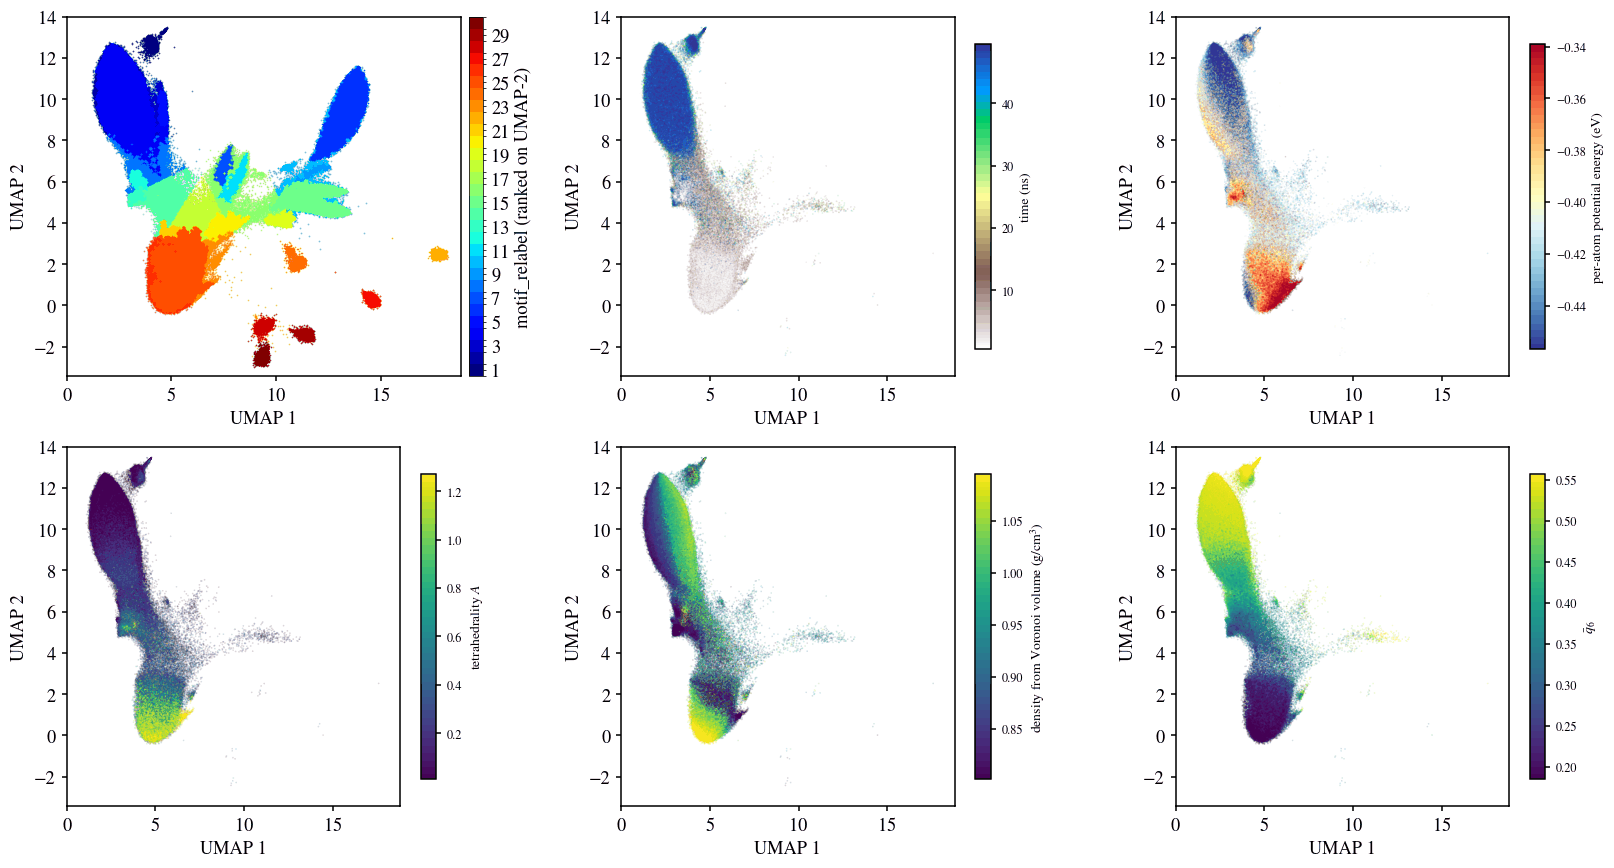

In [3]:
house_style()        # the published style, for the rest of this kernel

fig = plot_umap_by_properties(PUB_EMB, pooled_labels, src_emb[pub_idx],
                              pub_props, PUB_COLORS, PUB_ORDER,
                              f"{REPRO_DIR}/05-umap-by-properties{SUF}.png",
                              frame=PUB_FRAME, maxima=set(PUB_MAXIMA),
                              cbar=CBAR, mlabel=RANKLABEL)

    dist-merged: 4 of 4 panels carry data


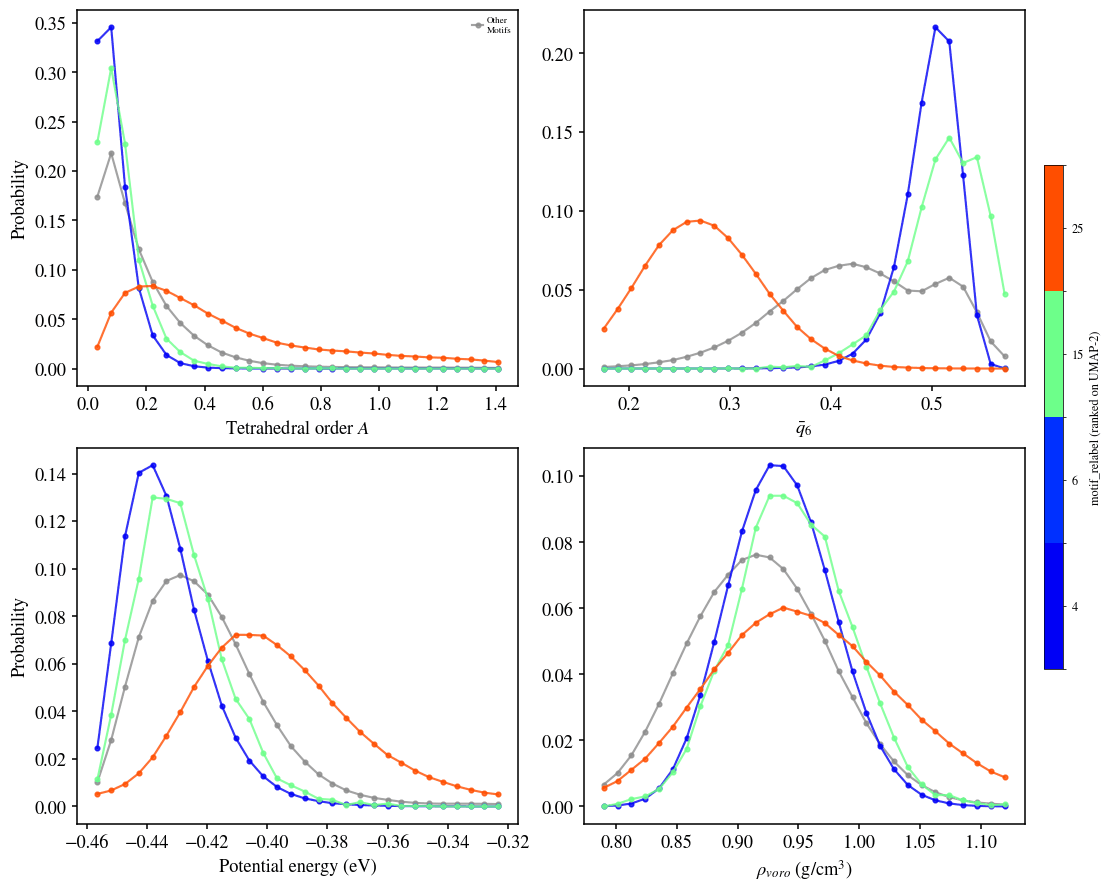

In [4]:
fig = plot_dist_merged({k: v for k, v in pub_props.items() if k != "time"},
                       src_labels[pub_idx], PUB_COLORS, PUB_ORDER, PUB_MAJOR,
                       f"{REPRO_DIR}/dist-merged.major{SUF}.png",
                       cbar=CBAR, mlabel=RANKLABEL)

    09-composition-ring-density: composition from 09-motif-composition-stacked.822188__8255188.NPT.T220.coarse20.csv


  reproduce-figures/ now holds:
    05-umap-by-properties.jet.png
    09-composition-ring-density.jet.png
    README.md
    dist-merged.major.jet.png

  house_style() is still in effect. Re-run the first cell of step 7 to
  go back to the style the package writes.


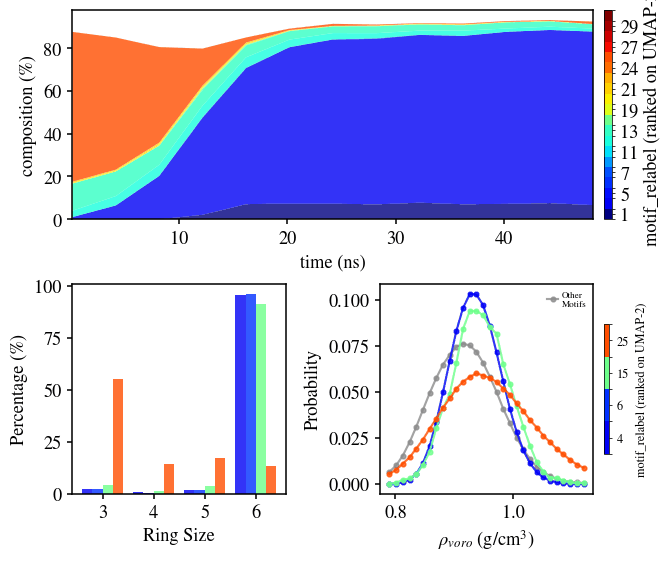

In [5]:
fig = plot_composition_ring_density(
    PUB_COMP, PUB_RINGS, pub_props, src_labels[pub_idx], PUB_COLORS,
    PUB_ORDER, PUB_MAJOR,
    f"{REPRO_DIR}/09-composition-ring-density{SUF}.png",
    cbar=CBAR, mlabel=RANKLABEL)

print(f"  {REPRO_DIR}/ now holds:")
for f in sorted(os.listdir(REPRO_DIR)):
    if not f.startswith("."):        # editor and checkpoint directories
        print(f"    {f}")
print("\n  house_style() is still in effect. Re-run the first cell of step 7 to"
      "\n  go back to the style the package writes.")

## What to quote from this

Report the **HDBSCAN cluster count** and the **intermediate fraction** from `run/motifs/clustering.json` — its `n_density_maxima` and `outlier_fraction` fields. The motif total adds a chosen number of k-means cells to a measured number, so on its own it reports a parameter as much as a result.

## The published result, for comparison

`reference/` holds the figures and a movie from the published analysis of this trajectory. Re-running retrains the VAE and refits the clustering, so your motif vocabulary will be your own — compare the structure of the answer, not the motif numbers. See the movie note in `examples/README.md`, which records where the movie's colours differ from the figures.

![motif map](reference/01-motif-map.png)

![populations over time](reference/08-motif-population-vs-frame.png)

![colour key](reference/00-legend-relabel.png)